# MLflow con un Pipeline de scikit-learn

Documentación oficial completa: [MLflow Scikit-learn Integration](https://mlflow.org/docs/latest/ml/traditional-ml/sklearn/)
y [Automatic Logging with MLflow Tracking](https://mlflow.org/docs/latest/ml/tracking/autolog/).

La documentación describe dos formas de usar las dos herramientas juntas, y este notebook
recorre ambas sobre un mismo `Pipeline`:

- **Autologging** (`mlflow.sklearn.autolog()`): MLflow intercepta `fit` y registra por su
  cuenta parámetros, métricas de entrenamiento y el modelo. Con `GridSearchCV` crea una
  ejecución padre y una hija por combinación.
- **Registro explícito** (`mlflow.sklearn.log_model`): se decide qué se guarda. Hace falta
  para lo que el autologging no puede saber: métricas con el nombre que el equipo usa,
  gráficos propios, la firma del modelo y su registro con versión.

El orden es el del ciclo CRISP-DM: preparación de datos, modelado y evaluación.

In [1]:
import logging
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import mlflow
import numpy as np
import pandas as pd

# El aviso sobre columnas enteras y valores faltantes no aplica: el generador no produce nulos.
warnings.filterwarnings("ignore", message=".*Inferred schema contains integer column.*")
# El entorno creado con uv no trae pip, y MLflow lo avisa cada vez que guarda un modelo.
logging.getLogger("mlflow.utils.environment").setLevel(logging.ERROR)

# Raiz de la actividad, se ejecute el notebook desde notebooks/ o desde la raiz.
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

# Almacen local: las ejecuciones van a una base SQLite y los artefactos a una carpeta.
# Ninguno de los dos se versiona.
mlflow.set_tracking_uri(f"sqlite:///{ROOT / 'mlflow.db'}")


def get_or_create_experiment(name, description):
    """Devuelve el id del experimento, creandolo si no existe."""
    experiment = mlflow.get_experiment_by_name(name)
    if experiment is not None:
        return experiment.experiment_id
    return mlflow.create_experiment(
        name,
        artifact_location=(ROOT / "mlartifacts").as_uri(),
        tags={"mlflow.note.content": description, "project": "apples-demand"},
    )


print("MLflow", mlflow.__version__)
print("Tracking URI:", mlflow.get_tracking_uri().replace(str(ROOT), "<raiz>"))

MLflow 3.17.1
Tracking URI: sqlite:///<raiz>/mlflow.db


In [2]:
experiment_id = get_or_create_experiment(
    "apples-demand-sklearn-pipeline",
    "Pipeline de scikit-learn registrado con MLflow: autologging, GridSearchCV y registro explicito.",
)
mlflow.set_experiment(experiment_id=experiment_id)
print("Experimento:", experiment_id)

Experimento: 2


## 1. Datos y partición temporal

Los datos salen del generador mejorado (ver `01_mlflow-tracking-tutorial.ipynb`). Esta vez
la columna `date` se conserva: el pipeline la convierte en variables.

In [3]:
from mlflow_workshop import TARGET_COLUMN, generate_apple_sales_data, split_by_time

data = generate_apple_sales_data(n_rows=5000, base_demand=1000)
X_train, X_test, y_train, y_test = split_by_time(data, TARGET_COLUMN, test_size=0.2)

print("Entrenamiento:", X_train["date"].min().date(), "a", X_train["date"].max().date(), X_train.shape)
print("Prueba:       ", X_test["date"].min().date(), "a", X_test["date"].max().date(), X_test.shape)
X_train.head(3)

Entrenamiento: 2011-04-25 a 2022-04-06 (4000, 10)
Prueba:        2022-04-07 a 2024-12-31 (1000, 10)


,date,average_temperature,rainfall,weekend,holiday,price_per_kg,promo,previous_days_demand,competitor_price_per_kg,marketing_intensity
0,2011-04-25,31.278603,1.851679,0,0,2.599977,1,1466.640528,2.251595,0.616025
1,2011-04-26,12.483144,0.033727,0,0,0.634884,1,1123.677119,0.789789,0.636920
2,2011-04-27,30.660568,1.473259,0,0,0.648268,1,1261.501327,0.831791,0.779411


## 2. El pipeline

`build_pipeline` (en `mlflow_workshop.pipeline`) encadena tres pasos:

1. `features`: un transformador propio, `DemandFeatures`, que deriva de la fecha el mes y
   los años transcurridos, y compara el precio propio con el de la competencia.
2. `preprocess`: un `ColumnTransformer` que escala las numéricas, deja pasar las binarias y
   codifica el mes.
3. `model`: el estimador, intercambiable.

Que el preprocesamiento viva dentro del pipeline es lo que hace útil registrarlo: el
artefacto guardado recibe datos crudos y devuelve predicciones, sin código de preparación
suelto que haya que repetir al usarlo.

In [4]:
from mlflow_workshop import build_pipeline

pipeline = build_pipeline()
pipeline

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('features', ...), ('preprocess', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,date_column,'date'
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('bin', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_thre

## 3. Autologging de un pipeline

Una sola línea antes de entrenar. `log_input_examples` y `log_datasets` hacen que también
queden un ejemplo de entrada y la referencia al conjunto de entrenamiento.

In [5]:
mlflow.sklearn.autolog(log_input_examples=True, log_datasets=True, max_tuning_runs=10, silent=True)

with mlflow.start_run(run_name="pipeline-ridge-autolog") as autolog_run:
    pipeline.fit(X_train, y_train)
    # Una metrica calculada despues de entrenar tambien se registra sola.
    test_r2 = pipeline.score(X_test, y_test)

print("R2 en prueba:", round(test_r2, 4))

R2 en prueba: 0.9424


No se llamó a `log_param` ni a `log_metric`. Esto es lo que MLflow registró:

In [6]:
client = mlflow.MlflowClient()
logged = client.get_run(autolog_run.info.run_id)

print("Parametros registrados:", len(logged.data.params))
print("Del paso 'model':", {k: v for k, v in logged.data.params.items() if k.startswith("model__")})
print("Artefactos:", [artifact.path for artifact in client.list_artifacts(autolog_run.info.run_id)])
pd.Series(logged.data.metrics, name="valor").round(4).to_frame()

Parametros registrados: 37
Del paso 'model': {'model__alpha': '1.0', 'model__copy_X': 'True', 'model__fit_intercept': 'True', 'model__max_iter': 'None', 'model__positive': 'False', 'model__random_state': 'None', 'model__solver': 'auto', 'model__tol': '0.0001'}
Artefactos: ['estimator.html', 'metric_info.json']


,valor
training_mean_squared_error,2787.3957
training_mean_absolute_error,42.1627
training_r2_score,0.9547
training_root_mean_squared_error,52.7958
training_score,0.9547
Pipeline_score_X_test,0.9424


Tres cosas a notar:

- Los parámetros son los de `pipeline.get_params()`: los de **todos** los pasos, con el
  prefijo del paso (`preprocess__num__with_mean`, `model__alpha`). Queda registrado cómo se
  prepararon los datos, no solo cómo se configuró el modelo.
- Las métricas `training_*` se calculan sobre el entrenamiento. Sirven para detectar
  sobreajuste al compararlas con las de prueba, no para elegir un modelo.
- `Pipeline_score_X_test` es una métrica posterior al entrenamiento: MLflow la registró al
  detectar la llamada a `score`, y la nombró con la variable que se le pasó.

## 4. GridSearchCV: una ejecución padre y sus hijas

La rejilla cambia el paso `model` completo, así que compara dos familias de modelos con el
mismo preprocesamiento. La validación cruzada es `TimeSeriesSplit`: cada pliegue valida con
días posteriores a los que usó para entrenar.

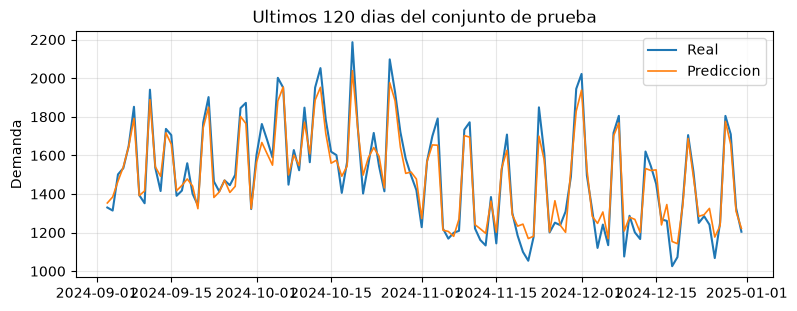

Mejor modelo: {'model': Ridge(), 'model__alpha': 0.1}
RMSE medio en validacion cruzada: 54.92


test_rmse    62.479
test_mae     49.428
test_r2       0.943
dtype: float64

In [7]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import Ridge
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit

from mlflow_workshop import regression_metrics

param_grid = [
    {"model": [Ridge()], "model__alpha": [0.1, 1.0, 10.0, 100.0]},
    {
        "model": [RandomForestRegressor(n_estimators=150, random_state=42)],
        "model__max_depth": [6, 12],
        "model__min_samples_leaf": [1, 10],
    },
]

with mlflow.start_run(run_name="pipeline-grid-search") as grid_run:
    search = GridSearchCV(
        build_pipeline(),
        param_grid,
        cv=TimeSeriesSplit(n_splits=5),
        scoring="neg_root_mean_squared_error",
        n_jobs=-1,
    )
    search.fit(X_train, y_train)

    # Lo que el autologging no sabe: metricas de prueba con nombres propios y un grafico.
    predictions = search.predict(X_test)
    test_metrics = regression_metrics(y_test, predictions, prefix="test_")
    mlflow.log_metrics(test_metrics)
    mlflow.set_tags({"stage": "tuning", "split": "temporal", "cv": "TimeSeriesSplit(5)"})

    fig, ax = plt.subplots(figsize=(9, 3.2))
    last = slice(-120, None)
    ax.plot(X_test["date"].iloc[last], y_test.iloc[last], label="Real", linewidth=1.5)
    ax.plot(X_test["date"].iloc[last], predictions[last], label="Prediccion", linewidth=1.2)
    ax.set_ylabel("Demanda")
    ax.set_title("Ultimos 120 dias del conjunto de prueba")
    ax.legend()
    ax.grid(alpha=0.3)
    mlflow.log_figure(fig, "plots/prediction-vs-actual.png")
    plt.show()

print("Mejor modelo:", search.best_params_)
print("RMSE medio en validacion cruzada:", round(-search.best_score_, 2))
pd.Series(test_metrics).round(3)

In [8]:
children = mlflow.search_runs(
    experiment_ids=[experiment_id],
    filter_string=f"tags.mlflow.parentRunId = '{grid_run.info.run_id}'",
    order_by=["metrics.rank_test_score ASC"],
)
summary = children[[
    "params.model", "params.model__alpha", "params.model__max_depth", "params.model__min_samples_leaf",
    "metrics.mean_test_score", "metrics.std_test_score", "metrics.rank_test_score",
]].copy()
summary["params.model"] = summary["params.model"].str.split("(").str[0]
# MLflow copia a cada hija los parametros del pipeline base, asi que las del bosque
# heredan el alpha del Ridge inicial. No les aplica y se quita de la tabla.
summary.loc[summary["params.model"] != "Ridge", "params.model__alpha"] = None
summary["cv_rmse"] = -summary.pop("metrics.mean_test_score")
summary.round(2)

,params.model,params.model__alpha,params.model__max_depth,params.model__min_samples_leaf,metrics.std_test_score,metrics.rank_test_score,cv_rmse
0,Ridge,0.1,NaN,NaN,3.25,1.0,54.92
1,Ridge,1.0,NaN,NaN,3.26,2.0,55.07
2,Ridge,10.0,NaN,NaN,2.98,3.0,57.29
3,Ridge,100.0,NaN,NaN,8.99,4.0,83.27
4,RandomForestRegressor,NaN,12,1,5.04,5.0,84.44
5,RandomForestRegressor,NaN,12,10,6.11,6.0,93.79
6,RandomForestRegressor,NaN,6,1,10.00,7.0,96.61
7,RandomForestRegressor,NaN,6,10,8.80,8.0,98.81


In [9]:
print("Artefactos de la ejecucion padre:")
for artifact in client.list_artifacts(grid_run.info.run_id):
    print(" -", artifact.path)

Artefactos de la ejecucion padre:
 - cv_results.csv
 - estimator.html
 - plots


La ejecución padre guarda la tabla completa de la validación cruzada (`cv_results.csv`), el
diagrama del estimador (`estimator.html`), los mejores parámetros con prefijo `best_` y el
mejor pipeline ya reentrenado. Cada hija guarda una combinación con su media y desviación
entre pliegues.

## 5. Registro explícito del pipeline ganador

El autologging ya guardó el modelo. Registrarlo a mano permite fijar la firma, elegir el
ejemplo de entrada y publicarlo en el Model Registry con un nombre y una versión.

Un detalle propio de los pipelines con pasos personalizados: MLflow 3 serializa los modelos
de scikit-learn con `skops`, que al cargar solo acepta tipos de una lista de confianza.
`DemandFeatures` es código de este taller y no está en esa lista, así que hay que declararlo
con `skops_trusted_types`. Sin eso, `log_model` falla y nombra los tipos que no reconoce.

In [10]:
from mlflow.models import infer_signature

mlflow.sklearn.autolog(disable=True)

MODEL_NAME = "apples-demand-pipeline"
best_pipeline = search.best_estimator_

with mlflow.start_run(run_name="pipeline-champion") as champion_run:
    mlflow.log_params({key: str(value).split("(")[0] if key == "model" else value for key, value in search.best_params_.items()})
    mlflow.log_metrics(test_metrics)
    mlflow.log_metric("cv_rmse", -search.best_score_)
    mlflow.set_tags({"stage": "champion", "source_run": grid_run.info.run_id})

    model_info = mlflow.sklearn.log_model(
        best_pipeline,
        name="pipeline",
        signature=infer_signature(X_train, best_pipeline.predict(X_train)),
        input_example=X_train.head(3),
        skops_trusted_types=["mlflow_workshop.pipeline.DemandFeatures"],
        registered_model_name=MODEL_NAME,
    )

    # Model Evaluation: metricas estandar de regresion calculadas por MLflow sobre el conjunto de prueba.
    evaluation = mlflow.models.evaluate(
        model_info.model_uri,
        pd.concat([X_test, y_test], axis=1),
        targets=TARGET_COLUMN,
        model_type="regressor",
        evaluator_config={"log_model_explainability": False},
    )

# Model Registry: el alias marca que version se usa, sin tocar el codigo que la consume.
client.set_registered_model_alias(MODEL_NAME, "champion", model_info.registered_model_version)
print(f"Registrado: {MODEL_NAME} version {model_info.registered_model_version}, alias 'champion'")
pd.Series(evaluation.metrics, name="valor").map("{:,.4f}".format).to_frame()

Successfully registered model 'apples-demand-pipeline'.
Created version '1' of model 'apples-demand-pipeline'.


2026/10/13 08:44:00 INFO mlflow.tracking.fluent: Active model is set to the logged model with ID: m-0f1d0879e059496cb754ea62c85438a4


2026/10/13 08:44:00 INFO mlflow.tracking.fluent: Use `mlflow.set_active_model` to set the active model to a different one if needed.


2026/10/13 08:44:01 INFO mlflow.models.evaluation.default_evaluator: Testing metrics on first row...


Registrado: apples-demand-pipeline version 1, alias 'champion'


,valor
score,0.9427
example_count,"1,000.0000"
mean_absolute_error,49.4280
mean_squared_error,"3,903.6163"
root_mean_squared_error,62.4789
sum_on_target,"1,453,827.4217"
mean_on_target,"1,453.8274"
r2_score,0.9427
max_error,188.6401
mean_absolute_percentage_error,0.0350


## 6. Cargar el pipeline y predecir con datos crudos

Quien consume el modelo lo pide por nombre y alias. Recibe el pipeline completo: le pasa
filas tal como salen del origen, con la fecha sin procesar.

In [11]:
champion = mlflow.pyfunc.load_model(f"models:/{MODEL_NAME}@champion")

raw_rows = X_test.tail(5)
result = raw_rows[["date", "price_per_kg", "promo", "weekend"]].copy()
result["real"] = y_test.tail(5).round(1)
result["prediccion"] = np.round(champion.predict(raw_rows), 1)
result

,date,price_per_kg,promo,weekend,real,prediccion
4995,2024-12-27,1.919662,0,0,1251.7,1235.9
4996,2024-12-28,2.912162,1,1,1804.5,1775.9
4997,2024-12-29,1.744910,0,1,1709.2,1656.3
4998,2024-12-30,1.513895,0,0,1327.3,1309.5
4999,2024-12-31,2.154600,0,0,1204.3,1221.5


In [12]:
print(champion.metadata.signature)

inputs: 
  ['date': datetime (required), 'average_temperature': double (required), 'rainfall': double (required), 'weekend': long (required), 'holiday': long (required), 'price_per_kg': double (required), 'promo': long (required), 'previous_days_demand': double (required), 'competitor_price_per_kg': double (required), 'marketing_intensity': double (required)]
outputs: 
  [Tensor('float64', (-1,))]
params: 
  None



## 7. Comparación de las ejecuciones del experimento

Una celda vacía (`NaN`) significa que esa ejecución no registró la métrica: el autologging
no calcula métricas de prueba con estos nombres, y la ejecución final no reentrena.

In [13]:
runs = mlflow.search_runs(experiment_ids=[experiment_id], order_by=["start_time DESC"])
# Solo las ejecuciones principales: las hijas de la rejilla ya se vieron arriba.
main_runs = runs[runs["tags.mlflow.parentRunId"].isna()].drop_duplicates("tags.mlflow.runName")
columns = ["tags.mlflow.runName", "metrics.training_root_mean_squared_error", "metrics.best_cv_score", "metrics.test_rmse", "metrics.test_r2"]
main_runs[columns].round(3)

,tags.mlflow.runName,metrics.training_root_mean_squared_error,metrics.best_cv_score,metrics.test_rmse,metrics.test_r2
0,pipeline-champion,NaN,NaN,62.479,0.943
7,pipeline-grid-search,52.794,-54.915,62.479,0.943
10,pipeline-ridge-autolog,52.796,NaN,NaN,NaN


## Qué queda registrado

| Necesidad | Cómo se resolvió | Funcionalidad de MLflow |
| :--- | :--- | :--- |
| Saber con qué configuración se entrenó cada modelo | Parámetros de todos los pasos del pipeline, sin escribir código | Autologging |
| Comparar combinaciones de una búsqueda | Ejecución padre con una hija por combinación de `GridSearchCV` | Scikit-learn Integration |
| Métricas de prueba y gráficos propios | `log_metrics` y `log_figure` dentro de la misma ejecución | Experiment Tracking |
| Validar el modelo con métricas estándar | `mlflow.models.evaluate` con `model_type="regressor"` | Model Evaluation |
| Usar el modelo sin repetir el preprocesamiento | Pipeline completo guardado con firma y recuperado por alias | Model Registry |

Para ver todo esto en la interfaz, desde la raíz de la actividad:

```bash
uv run mlflow ui --backend-store-uri sqlite:///mlflow.db --port 5000
```